# Phishing Website Detection Using Machine Learning
**Course:** Information Security Lab | **Group 9**
**Members:** Tanseer Haider, Hassan Ameer Ahmad, M. Arham

## Module 2: Data Cleaning and Exploratory Data Analysis (EDA)

**Goal:** Clean the dataset (remove duplicates) and explore it with charts to see which features separate phishing from legitimate websites.

**What is EDA?** Exploratory Data Analysis means *looking at the data with tables and charts before training any model*. It tells us how the data is shaped, whether it has problems, and which features look useful.

**Steps in this module**
1. Load the data (from Module 1)
2. Remove duplicates and verify
3. Class balance chart (before vs after cleaning)
4. Feature vs label charts
5. Correlation heatmap
6. Top features related to the label
7. Highly correlated feature pairs
8. Save the cleaned data
9. Summary and conclusions

## Step 1: Install, import and load the data

In [16]:
!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=327)
X = data.data.features
y = data.data.targets

# Join features and label into ONE table and give the label a simple name
df = pd.concat([X, y], axis=1)
df = df.rename(columns={y.columns[0]: "result"})

print("Rows and columns:", df.shape)
print("Label column    :", "result  (-1 = Phishing, 1 = Legitimate)")

Rows and columns: (11055, 31)
Label column    : result  (-1 = Phishing, 1 = Legitimate)


## Step 2: Remove duplicates

**Why?** In Module 1 we found 5,206 repeated rows (47%). If the same website appears in both the training set and the test set, the model has already "seen" the test answer, and the score looks better than it really is. This is called **data leakage**.

In [17]:
rows_before = len(df)
dups_before = df.duplicated().sum()

df_clean = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df_clean)
dups_after = df_clean.duplicated().sum()

print("Rows before cleaning :", rows_before)
print("Duplicates found     :", dups_before)
print("Rows after cleaning  :", rows_after)
print("Duplicates remaining :", dups_after)

Rows before cleaning : 11055
Duplicates found     : 5206
Rows after cleaning  : 5849
Duplicates remaining : 0


In [18]:
# Verify cleaning: no missing values, no duplicates, all values still valid
print("Missing values after cleaning:", df_clean.isnull().sum().sum())
print("Duplicates after cleaning    :", df_clean.duplicated().sum())
print("Rows removed                 : {:.1f}%".format((rows_before - rows_after) / rows_before * 100))

Missing values after cleaning: 0
Duplicates after cleaning    : 0
Rows removed                 : 47.1%


## Step 3: Class balance (before vs after cleaning)

**Why?** Removing duplicates can change the phishing / legitimate ratio. We check that the classes are still reasonably balanced.

BEFORE cleaning:
result
Phishing      4898
Legitimate    6157
Name: count, dtype: int64

AFTER cleaning:
result
Phishing      3019
Legitimate    2830
Name: count, dtype: int64

Share after cleaning (%):
result
Phishing      51.6
Legitimate    48.4
Name: count, dtype: float64


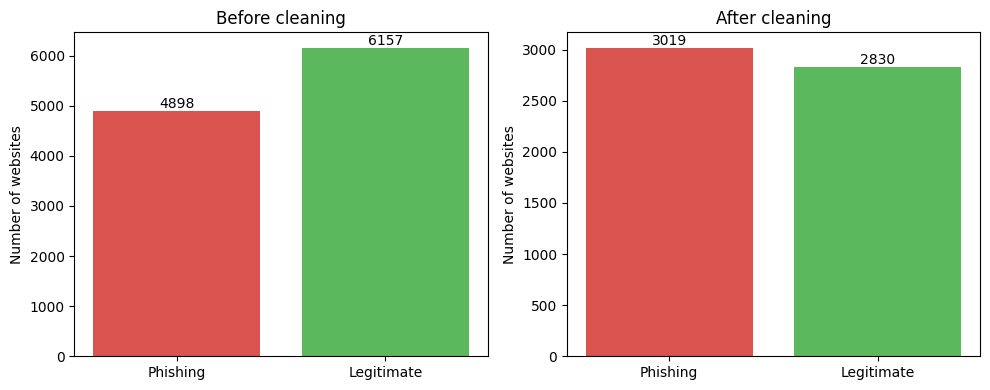

In [19]:
names = {-1: "Phishing", 1: "Legitimate"}
color_map = {-1: "#d9534f", 1: "#5cb85c"}

before = df["result"].value_counts().sort_index()
after = df_clean["result"].value_counts().sort_index()

print("BEFORE cleaning:")
print(before.rename(names))
print()
print("AFTER cleaning:")
print(after.rename(names))
print()
print("Share after cleaning (%):")
print((after / after.sum() * 100).round(1).rename(names))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, counts, title in zip(axes, [before, after], ["Before cleaning", "After cleaning"]):
    ax.bar([names[i] for i in counts.index], counts.values, color=[color_map[i] for i in counts.index])
    ax.set_title(title)
    ax.set_ylabel("Number of websites")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Step 4: Feature vs label charts

**Why?** To see whether a feature really separates phishing from legitimate websites. If the red and green bars look very different for a feature, that feature is useful.

We chose 5 important and easy-to-explain security features:
- `sslfinal_state`: status of the HTTPS / SSL certificate
- `url_of_anchor`: where the links on the page point to
- `web_traffic`: how popular the website is
- `having_ip_address`: whether the URL uses an IP address instead of a name
- `prefix_suffix`: whether the domain has a "-" in its name

(Values: -1 = phishing-like, 0 = suspicious, 1 = legitimate-like)

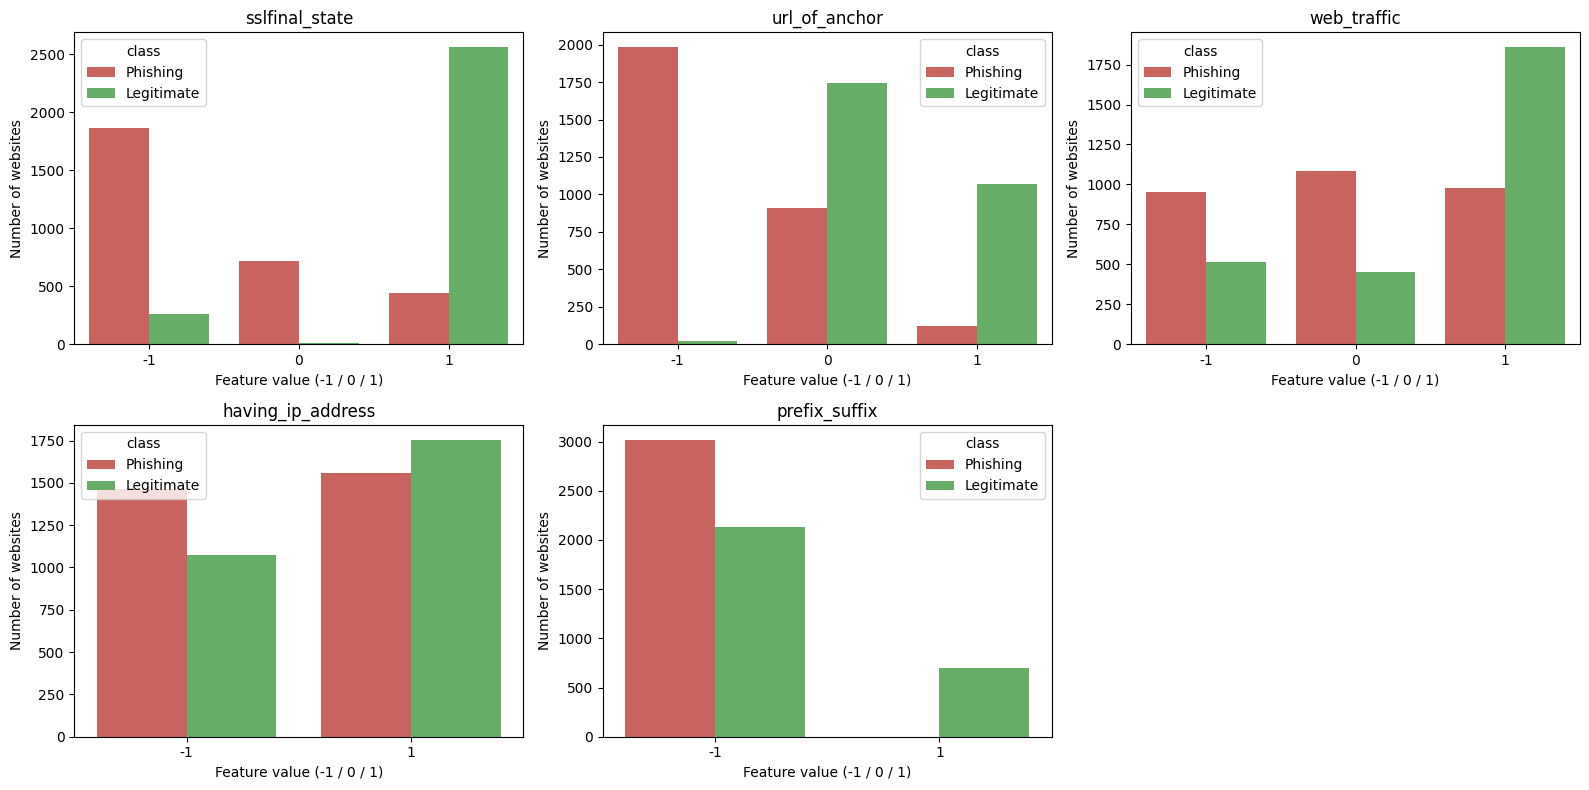

In [20]:
key_features = ["sslfinal_state", "url_of_anchor", "web_traffic", "having_ip_address", "prefix_suffix"]

plot_df = df_clean.copy()
plot_df["class"] = plot_df["result"].map(names)
palette = {"Phishing": "#d9534f", "Legitimate": "#5cb85c"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, f in zip(axes, key_features):
    sns.countplot(data=plot_df, x=f, hue="class", hue_order=["Phishing", "Legitimate"],
                  palette=palette, ax=ax)
    ax.set_title(f)
    ax.set_xlabel("Feature value (-1 / 0 / 1)")
    ax.set_ylabel("Number of websites")
axes[-1].axis("off")   # hide the empty 6th box
plt.tight_layout()
plt.show()

In [21]:
# Same idea as numbers: % of phishing sites for each feature value
for f in key_features:
    table = pd.crosstab(df_clean[f], df_clean["result"].map(names), normalize="index") * 100
    print(f"--- {f}: % of websites in each class, for each feature value ---")
    print(table.round(1))
    print()

--- sslfinal_state: % of websites in each class, for each feature value ---
result          Legitimate  Phishing
sslfinal_state                      
-1                    12.4      87.6
 0                     1.0      99.0
 1                    85.3      14.7

--- url_of_anchor: % of websites in each class, for each feature value ---
result         Legitimate  Phishing
url_of_anchor                      
-1                    0.9      99.1
 0                   65.6      34.4
 1                   89.6      10.4

--- web_traffic: % of websites in each class, for each feature value ---
result       Legitimate  Phishing
web_traffic                      
-1                 35.1      64.9
 0                 29.5      70.5
 1                 65.5      34.5

--- having_ip_address: % of websites in each class, for each feature value ---
result             Legitimate  Phishing
having_ip_address                      
-1                       42.4      57.6
 1                       53.0      47.0

## Step 5: Correlation heatmap

**What is correlation?** A number from -1 to +1 that shows how strongly two columns move together.
- Close to **+1**: when one goes up, the other goes up.
- Close to **-1**: when one goes up, the other goes down.
- Close to **0**: no clear relationship.

The heatmap colours these numbers: red = positive, blue = negative, white = near zero.

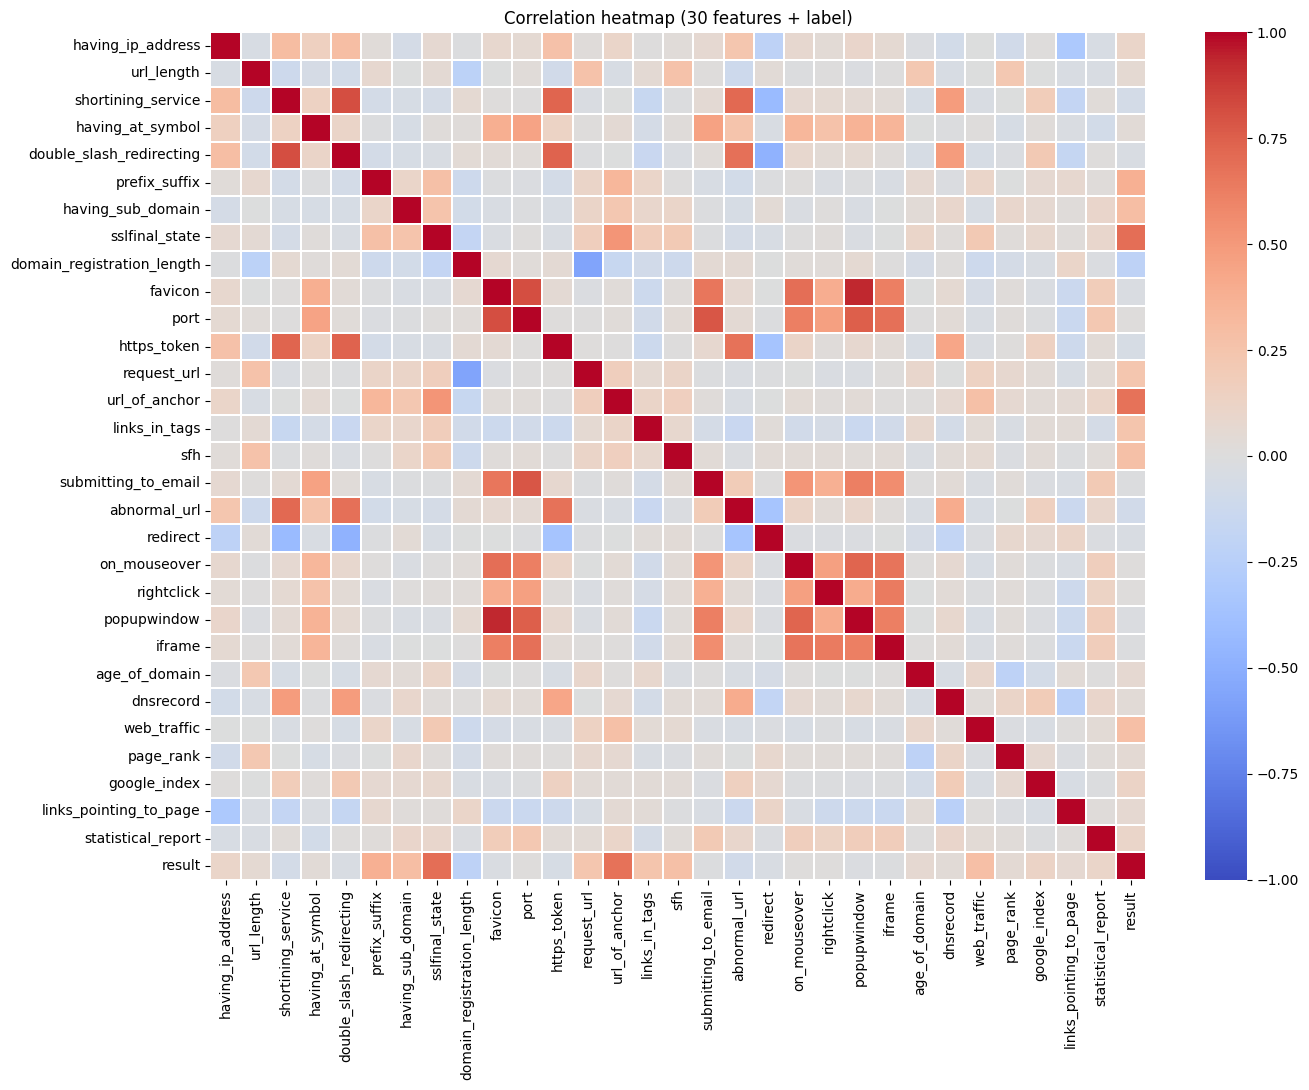

In [22]:
corr = df_clean.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, linewidths=0.3)
plt.title("Correlation heatmap (30 features + label)")
plt.tight_layout()
plt.show()

## Step 6: Top features related to the label

We take the correlation of every feature with the label (`result`). Because **1 = Legitimate**:
- a **positive** correlation means a higher feature value goes with *legitimate* websites,
- a **negative** correlation means a higher feature value goes with *phishing* websites.

We rank by the absolute value (the strength), ignoring the sign.

,correlation_with_label
feature,
sslfinal_state,0.693
url_of_anchor,0.679
prefix_suffix,0.381
having_sub_domain,0.296
web_traffic,0.282
sfh,0.281
links_in_tags,0.244
request_url,0.238
domain_registration_length,-0.219


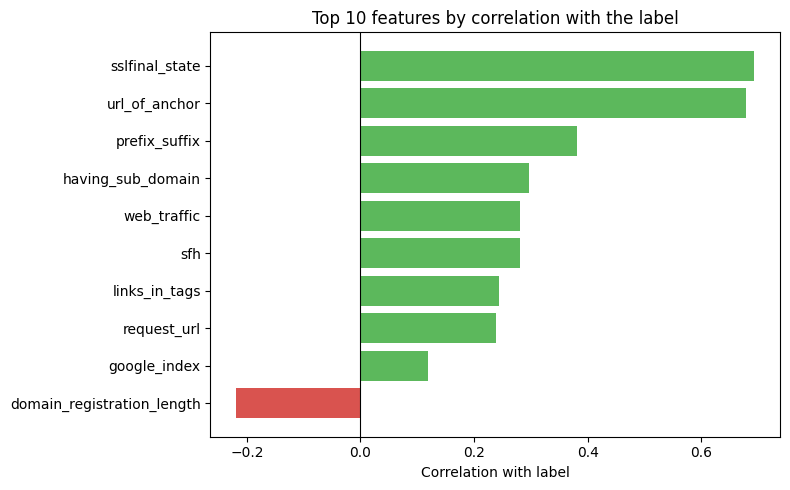

In [23]:
corr_label = corr["result"].drop("result")
top10 = corr_label.abs().sort_values(ascending=False).head(10).index

top_table = pd.DataFrame({"correlation_with_label": corr_label[top10].round(3)})
top_table.index.name = "feature"
display(top_table)

plt.figure(figsize=(8, 5))
vals = corr_label[top10].sort_values()
plt.barh(vals.index, vals.values, color=["#d9534f" if v < 0 else "#5cb85c" for v in vals.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 features by correlation with the label")
plt.xlabel("Correlation with label")
plt.tight_layout()
plt.show()

## Step 7: Highly correlated feature pairs

If two features carry almost the same information (correlation above 0.7 or below -0.7), we should know about it. This is called **multicollinearity**. It matters mostly for simple models like Logistic Regression.

In [24]:
corr_feat = df_clean.drop(columns="result").corr()
upper = corr_feat.where(np.triu(np.ones(corr_feat.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "correlation"]
high = pairs[pairs["correlation"].abs() > 0.7].sort_values("correlation", key=abs, ascending=False)

if len(high) == 0:
    print("No feature pair has |correlation| above 0.7.")
else:
    display(high.round(3).reset_index(drop=True))

,feature_1,feature_2,correlation
0,favicon,popupwindow,0.933
1,shortining_service,double_slash_redirecting,0.816
2,favicon,port,0.813
3,port,submitting_to_email,0.785
4,port,popupwindow,0.755
5,double_slash_redirecting,https_token,0.737
6,on_mouseover,popupwindow,0.732
7,shortining_service,https_token,0.730
8,shortining_service,abnormal_url,0.712


## Step 8: Save the cleaned data (for Module 3)

In [25]:
df_clean.to_csv("phishing_clean.csv", index=False)
print("Saved phishing_clean.csv with", df_clean.shape[0], "rows and", df_clean.shape[1], "columns")

# Optional: download it to your computer, then upload it to GitHub
# from google.colab import files
# files.download("phishing_clean.csv")

Saved phishing_clean.csv with 5849 rows and 31 columns


## Step 9: Module 2 summary

In [26]:
print("=== MODULE 2 SUMMARY ===")
print("Rows before cleaning   :", rows_before)
print("Duplicates removed     :", dups_before)
print("Rows after cleaning    :", rows_after)
print("Missing values         :", df_clean.isnull().sum().sum())
print("Phishing / Legitimate  :", after.get(-1, 0), "/", after.get(1, 0))
print("Top 5 features by correlation with the label:")
for f in top10[:5]:
    print("   ", f, "->", round(corr_label[f], 3))
print("Next (Module 3)        : split the data 80/20 and train baseline models")

=== MODULE 2 SUMMARY ===
Rows before cleaning   : 11055
Duplicates removed     : 5206
Rows after cleaning    : 5849
Missing values         : 0
Phishing / Legitimate  : 3019 / 2830
Top 5 features by correlation with the label:
    sslfinal_state -> 0.693
    url_of_anchor -> 0.679
    prefix_suffix -> 0.381
    having_sub_domain -> 0.296
    web_traffic -> 0.282
Next (Module 3)        : split the data 80/20 and train baseline models


## Conclusions (write these after reading your own charts)
1. After removing duplicates we have 5,849 unique websites (5,206 duplicate rows removed, 47.1%).
2. The classes are still fairly balanced, with 51.6% phishing (3,019) and 48.4% legitimate (2,830).
3. The features most related to the label are sslfinal_state (0.693), url_of_anchor (0.679) and prefix_suffix (0.381).
4. In the feature-vs-label charts, sslfinal_state = -1 mostly means phishing (87.6% of those websites are phishing), and sslfinal_state = 1 mostly means legitimate (85.3%).
5. The heatmap shows some strongly correlated feature pairs: 9 pairs above 0.7, the strongest being favicon and popupwindow (0.933).
6. Next step: split the cleaned data 80/20 and train the baseline models (Module 3).
